We implement three ansatzes for the VQE algorithm based on the mqchem module in mindquantum: UCCSD, SymUCCSD and HiUCCSD.

## A. UCCSD

As a classic variational quantum eigensolver ansatz, the UCCSD (Unitary Coupled-Cluster Singles and Doubles) method [1] is derived from the traditional coupled-cluster theory and extended to the quantum computing framework by constructing unitary excitation operators. It aims to accurately describe the electron correlation effects in molecular systems and solve the ground state energy problem of molecules. The specific implementation process of this method is as follows:

- Based on the number of molecular orbitals and electrons, define the complete set of single and double excitation operators covering all possible electron excitation channels;
- Construct unitary evolution operators for each excitation operator, and parameterize them with variational parameters to form the basic building blocks of the ansatz;
- Assemble all single and double excitation unitary operators in a product form to generate the full UCCSD ansatz, which includes all possible single (from occupied to virtual orbitals) and double electron excitation processes.


## B. SymUCCSD

To address the problem of excessive quantum circuit depth in the UCCSD ansatz, the SymUCCSD (symmetry-constrained unitary coupled-cluster singles and doubles) method [2] takes molecular point group symmetry as the core constraint and constructs a more compact ansatz by screening out excitation operators that do not satisfy the molecular point group symmetry requirements. The specific implementation process of this method is as follows:

- Determine the point group to which the molecule belongs based on its geometric structure;
- Derive the irreducible representations (irrps) corresponding to each molecular orbital and construct the corresponding irrep product table;
- Clarify the irrep of the reference state according to the involved molecular orbitals;
- Calculate the irrep of the excited state generated by the action of each excitation operator;
- Filter out all excitation operators in the ansatz for which the irrep of the corresponding excited state is different from that of the reference state.

Here, we automate the above steps based on the PySCF software package, use the mqchem module to execute the constructed ansatz, and calculate the ground state energy of the hydrogen fluoride (HF) molecule.

## C. HiUCCSD

To overcome the over-parameterization and high computational cost of the full UCCSD ansatz while maintaining sufficient accuracy, the HiUCCSD (Hamiltonian-Informed Unitary Coupled-Cluster Singles and Doubles) method [3] takes the molecular Hamiltonian as the core constraint and constructs a streamlined ansatz by retaining only excitation operators that have non-negligible matrix elements with the Hamiltonian. The specific implementation process of this method is as follows:

- Input a coupled-cluster excitations $\hat{T}$ and the second-quantized molecular Hamiltonian.

- For each possible excitation operator $\hat{t}$ in $T$:

- $\qquad$ If the coefficients (electronic integrals) of $\hat{t}$ in the Hamiltonian is zero:

- $\qquad\qquad$ Remove $\hat{t}$ from $T$.

- Construct the symmetry-respecting ansatz $e^{\hat{T}-\hat{T^{\dagger}}}$ by the reduced $\hat{T}$.


In [ ]:
from tools import *
from algorithms import *
from mindquantum import *


geo = get_HF_geometry()
# geo = get_LiH_geometry()
# geo = get_H2O_geometry()
# geo = get_BeH2_geometry()
# geo = get_NH3_geometry()
# geo = get_CH4_geometry()
# geo = get_N2_geometry()
# geo = get_CO_geometry()
# geo = get_NaH_geometry()
# geo = get_C2H4_geometry()


hf, fci, ham, n_qubits, n_electrons = get_mole_info(geo)
sim = mqchem.MQChemSimulator(n_qubits, n_electrons)
print("\n关联能为", abs(hf-fci))

uccsd = get_uccsd(n_qubits, n_electrons)

symmetry = True 
symmetry = 'C2v'
# symmetry = 'D2h'
# symmetry = 'Cs'
# symmetry = 'D2'

symuccsd = get_symuccsd(geo, uccsd, n_electrons, symmetry)
hiuccsd = get_hiuccsd(ham, uccsd)

print(f"uccsd, symuccsd, hiuccsd 的参数量分别为")
print(len(sum(uccsd).params_name), len(sum(symuccsd).params_name), len(sum(hiuccsd).params_name))

print(f"\nuccsd, sym-uccsd, pra-uccsd 的激发算符数分别为")
print(len(uccsd), len(symuccsd),  len(hiuccsd))

symuccsd_res, _ = run_vqe(sim, ham, get_circ(symuccsd))
print('\nsymuccsd error', abs(fci-symuccsd_res))

hiuccsd_res, _ = run_vqe(sim, ham, get_circ(hiuccsd))
print('hiuccsd error', abs(fci-hiuccsd_res))

uccsd_res, _ = run_vqe(sim, ham, get_circ(uccsd))
print('uccsd error', abs(fci-uccsd_res))

print("\nsymuccsd, hiuccsd, uccsd, 的计算误差分别为")
print(abs(fci-symuccsd_res), abs(fci-hiuccsd_res), abs(fci-uccsd_res))



关联能为 0.03278481540166922
uccsd, symuccsd, hiuccsd 的参数量分别为
20 11 11

uccsd, sym-uccsd, pra-uccsd 的激发算符数分别为
35 17 17

symuccsd error 8.820829435762789e-07
hiuccsd error 8.820830146305525e-07
uccsd error 8.820829293654242e-07

symuccsd, hiuccsd, uccsd, 的计算误差分别为
8.820829435762789e-07 8.820830146305525e-07 8.820829293654242e-07


## ADAPT-VQE

The ADAPT-VQE (Adaptive Derivative-Assembled Pseudo-Trotter ansatz Variational Quantum Eigensolver) algorithm [4] adopts the core idea of dynamically constructing the ansatz: first, all excitation operators included in the UCCSD ansatz are integrated into a complete "excitation operator pool", and key excitation operators are gradually selected through an iterative optimization mechanism to finally form a compact ansatz adapted to the target molecular system.

Its specific iterative process is as follows:
- Initialize an empty ansatz and reference state, and set termination conditions such as gradient threshold;
- In each iteration, calculate the energy gradient of all excitation operators in the excitation operator pool at the current ansatz state with parameters set to 0;
- Select the excitation operator with the largest absolute gradient value (i.e., the operator that contributes most significantly to energy reduction) and add it to the ansatz;
- Optimize all parameters of the current ansatz until convergence, then proceed to the next iteration;
- If in a certain iteration, the norm of the gradient vector of all remaining excitation operators in the operator pool is less than the preset threshold, terminate the iteration.

ADAPT-VQE has significant methodological advantages: first, this method can automatically select the most critical excitation operators to construct a compact ansatz with shallow circuit depth; second, by adjusting termination conditions such as the gradient threshold, it can in principle approach the requirement of arbitrary precision; finally, it adopts the "warm-start" optimization strategy, which directly reuses the optimal parameters from previous iterations after adding new excitation operators—this not only improves convergence efficiency but also effectively alleviates the common local optimum problem and barren plateau phenomenon in quantum optimization.

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from tools import *
from algorithms import *
from mindquantum import *
import json
from tqdm import tqdm


def to_save(file_path:str, mole:str, method:str, data_type:str, data):
    """将数据存到目标中, mole=LiH, method=uccsd, data_type=errors, data=list"""
    with open(file_path, "r", encoding="utf-8") as f:
        target = json.load(f)  # 直接解析JSON字符串为字典
    
    if mole not in target:
        target[mole] = {}

    if method not in target[mole]:
        target[mole][method] = {}
    
    target[mole][method][data_type] = data

    with open(file_path, "w", encoding="utf-8") as f:
        json.dump(target, f, ensure_ascii=False, indent=4)


def analize(geo:list, tol, symmetry=True):
    hf, fci, ham, n_qubits, n_electrons = get_mole_info(geo)
    uccsd = get_uccsd(n_qubits, n_electrons, False)
    hi_uccsd = get_hiuccsd(ham, uccsd)
    sym_uccsd = get_symuccsd(geo, uccsd, n_electrons, symmetry)
    
    energys_0, errors_0 = run_adapt_vqe(geo, uccsd, len(uccsd), tol)
    energys_1, errors_1 = run_adapt_vqe(geo, hi_uccsd, len(uccsd), tol)
    energys_2, errors_2 = run_adapt_vqe(geo, sym_uccsd, len(uccsd), tol)
    
    return energys_0[-1], energys_1[-1], energys_2[-1], errors_0[-1], errors_1[-1], errors_2[-1], hf, fci, len(errors_0)-1, len(errors_1)-1, len(errors_2)-1


tol = 1e-3
file_path = 'adapt_data.txt'

mole = 'LiH'
# mole = 'H2O'
# mole = 'NH3'

if mole == 'LiH':
    dist_range = [0.9, 2.4]
    dists = get_bound_list(dist_range, 11)
    geos = [get_LiH_geometry(dist) for dist in dists]
elif mole == 'H2O':
    dist_range = [0.6, 2.1]
    dists = get_bound_list(dist_range, 11)
    geos = [get_H2O_geometry(dist) for dist in dists]
else:
    dist_range = [0.6, 2.0]
    dists = get_bound_list(dist_range, 11)
    geos = [get_NH3_geometry(dist) for dist in dists]


for method in ['UCCSD', 'HiUCCSD', 'SymUCCSD']:
    to_save(file_path, mole, method, 'geos', geos)
    to_save(file_path, mole, method, 'dists', dists)

uccsd_errors, hi_errors, sym_errors = [], [], []
uccsd_energys, hi_energys, sym_energys = [], [], []
hfs, fcis = [], []
uccsd_iters, hi_iters, sym_iters = [], [], []

for geo in tqdm(geos):
    energy_0, energy_1, energy_2, error_0, error_1, error_2, hf, fci, iter_0, iter_1, iter_2 = analize(geo, tol)
    uccsd_energys.append(energy_0)
    hi_energys.append(energy_1)
    sym_energys.append(energy_2)
    uccsd_errors.append(error_0)
    hi_errors.append(error_1)
    sym_errors.append(error_2)
    hfs.append(hf)
    fcis.append(fci)
    uccsd_iters.append(iter_0)
    hi_iters.append(iter_1)
    sym_iters.append(iter_2)
    print(mole, error_2, error_1, error_0)

# to_save(file_path, mole, 'UCCSD', 'energys', uccsd_energys)
# to_save(file_path, mole, 'HiUCCSD', 'energys', hi_energys)
# to_save(file_path, mole, 'SymUCCSD', 'energys', sym_energys)
# to_save(file_path, mole, 'UCCSD', 'errors', uccsd_errors)
# to_save(file_path, mole, 'HiUCCSD', 'errors', hi_errors)
# to_save(file_path, mole, 'SymUCCSD', 'errors', sym_errors)
# to_save(file_path, mole, 'UCCSD', 'hfs', hfs)
# to_save(file_path, mole, 'UCCSD', 'fcis', fcis)
# to_save(file_path, mole, 'UCCSD', 'iters', uccsd_iters)
# to_save(file_path, mole, 'HiUCCSD', 'iters', hi_iters)
# to_save(file_path, mole, 'SymUCCSD', 'iters', sym_iters)

  9%|▉         | 1/11 [01:19<13:10, 79.02s/it]

LiH 6.367130645834607e-06 6.3671306413937145e-06 6.367130628959217e-06


 18%|█▊        | 2/11 [02:41<12:10, 81.18s/it]

LiH 6.052245158372216e-06 6.052263310074579e-06 6.052264395428608e-06


 27%|██▋       | 3/11 [04:03<10:49, 81.23s/it]

...

LiH 2.2260198054624425e-05 2.2260118353933933e-05 2.2260117932937362e-05


 91%|█████████ | 10/11 [12:49<01:13, 73.94s/it]

LiH 2.927136949004705e-05 2.9271370189931645e-05 2.927137010289016e-05


100%|██████████| 11/11 [14:02<00:00, 76.55s/it]

LiH 3.851033491208966e-05 3.8510334888108844e-05 3.851033496449219e-05


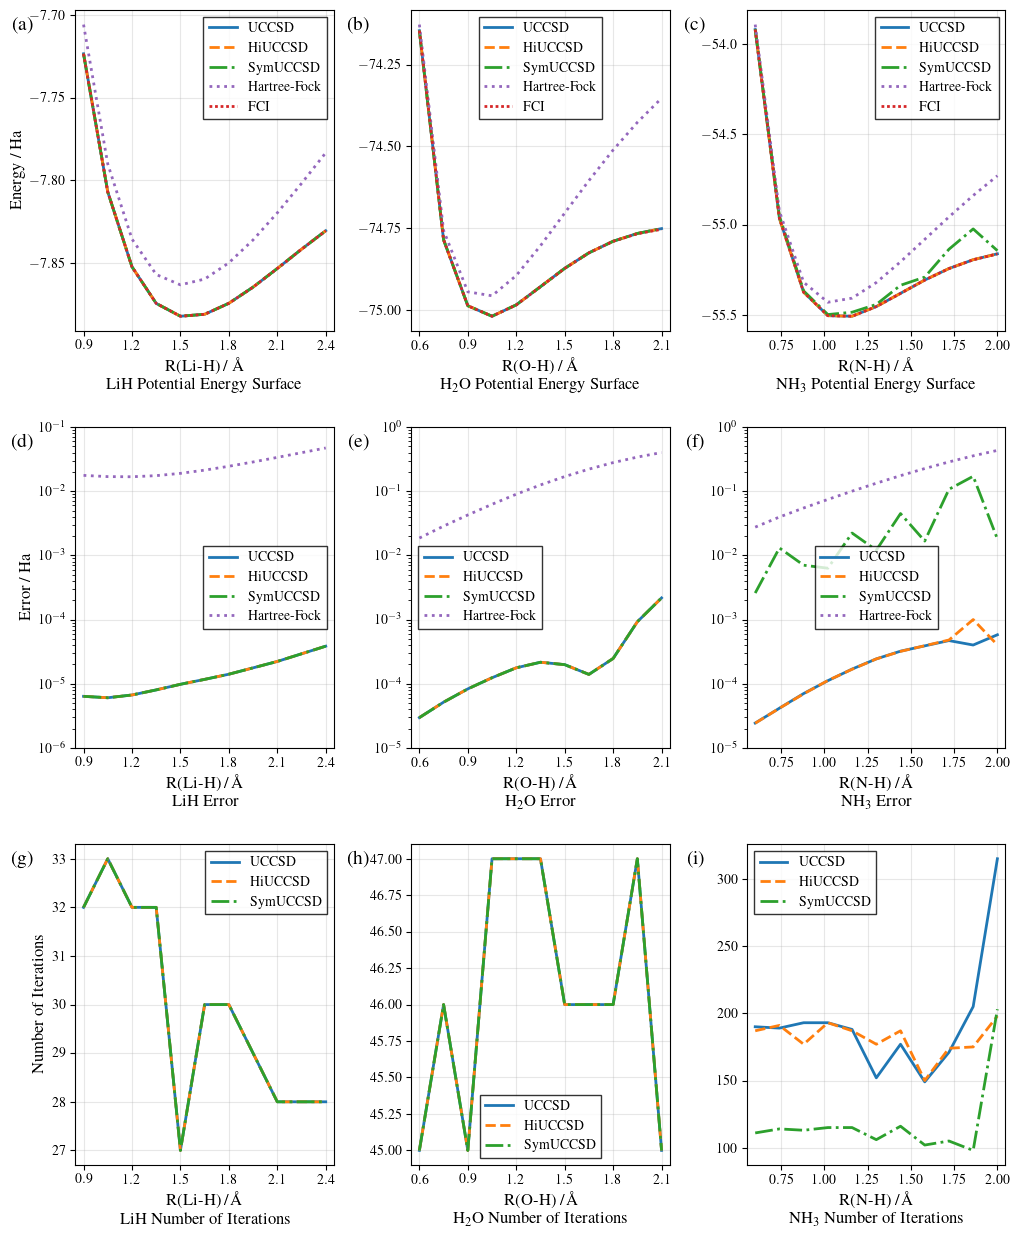

In [5]:
import numpy as np
import json
import matplotlib.pyplot as plt
from matplotlib.ticker import LogFormatterSciNotation, MaxNLocator

# Global font and LaTeX configuration
plt.rcParams['text.usetex'] = True  # Enable LaTeX rendering (LaTeX must be installed on the system)
plt.rcParams['font.family'] = 'serif'  # Serif font
plt.rcParams['font.serif'] = ['Times New Roman', 'Times']  # Prioritize Times New Roman
plt.rcParams['axes.unicode_minus'] = False  # Fix negative sign display issue

def plot_energys(ax, mole, dists, uccsd_energys, hi_energys, sym_energys, hfs, fcis):
    """Plot energy curves (takes external ax object)"""
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#d62728']
    # Plot curves
    ax.plot(dists, uccsd_energys, linestyle='-', linewidth=2, label='UCCSD', color=colors[0])
    ax.plot(dists, hi_energys, linestyle='--', linewidth=2, label='HiUCCSD', color=colors[1])
    ax.plot(dists, sym_energys, linestyle='-.', linewidth=2, label='SymUCCSD', color=colors[2])
    ax.plot(dists, hfs, linestyle=':', linewidth=2, label='Hartree-Fock', color=colors[3])
    ax.plot(dists, fcis, linestyle=(0, (1, 1)), linewidth=2, label='FCI', color=colors[4])
    # X-axis label
    if mole == 'LiH':
        ax.set_xlabel(r'R(Li-H) / $\mathrm{\AA}$' + '\n' + r'$\mathrm{LiH}$' + ' Potential Energy Surface', fontsize=12)
        # Y-axis label
        ax.set_ylabel(r'Energy / Ha', fontsize=12, fontname='Times New Roman')
    elif mole == 'H2O':
        ax.set_xlabel(r'R(O-H) / $\mathrm{\AA}$' + '\n' + r'$\mathrm{H_2O}$'  + ' Potential Energy Surface', fontsize=12)
    else:
        ax.set_xlabel(r'R(N-H) / $\mathrm{\AA}$' + '\n' + r'$\mathrm{NH_3}$'  + ' Potential Energy Surface', fontsize=12)
    # X-axis range and ticks
    marge = (dists[-1] - dists[0])/30
    ax.set_xlim(dists[0]-marge, dists[-1]+marge)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=False))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=False))
    # Tick parameters
    ax.tick_params(axis='both', labelsize=10)
    # Legend and grid
    ax.legend(fontsize=10, frameon=True, fancybox=False, edgecolor='black')
    ax.grid(True, alpha=0.3)

def plot_errors(ax, mole, dists, uccsd_errors, hi_errors, sym_errors, hfs, fcis):
    """Plot error curves (takes external ax object)"""
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#d62728']
    hf_errors = abs(np.array(hfs) - np.array(fcis))
    # Plot curves
    ax.plot(dists, uccsd_errors, linestyle='-', linewidth=2, label='UCCSD', color=colors[0])
    ax.plot(dists, hi_errors, linestyle='--', linewidth=2, label='HiUCCSD', color=colors[1])
    ax.plot(dists, sym_errors, linestyle='-.', linewidth=2, label='SymUCCSD', color=colors[2])
    ax.plot(dists, hf_errors, linestyle=':', linewidth=2, label='Hartree-Fock', color=colors[3])
    # Y-axis logarithmic scale
    ax.set_yscale('log')

    # Custom log scale formatter: ensure display in 10^-n format
    class CustomLogFormatter(LogFormatterSciNotation):
        def __call__(self, x, pos=None):
            if x <= 0:  # Avoid log calculation error (no 0 or negative values on log axis)
                return ''
            log_x = np.log10(x)
            # Round to display as 10^-n (n is integer)
            log_x_int = int(np.floor(log_x) if log_x < 0 else np.ceil(log_x))
            return r'$10^{%d}$' % (log_x_int)
    
    # Apply formatter
    ax.yaxis.set_major_formatter(CustomLogFormatter())
    # Manually set Y-axis ticks to integer powers of 10
    all_errors = np.concatenate([uccsd_errors, hi_errors, sym_errors, hf_errors])
    min_err = np.min(all_errors[all_errors > 0])
    max_err = np.max(all_errors)
    min_log = int(np.floor(np.log10(min_err)))
    max_log = int(np.ceil(np.log10(max_err)))
    y_ticks = [10**i for i in range(min_log, max_log + 1)]
    ax.set_yticks(y_ticks)

    # X-axis label
    if mole == 'LiH':
        ax.set_xlabel(r'R(Li-H) / $\! \mathrm{\AA}$' + '\n' + r'$\mathrm{LiH\ Error}$', fontsize=12)
        ax.set_ylabel(r'Error / Ha', fontsize=12, fontname='Times New Roman')
    elif mole == 'H2O':
        ax.set_xlabel(r'R(O-H) / $\! \mathrm{\AA}$' + '\n' + r'$\mathrm{H_2O\ Error}$', fontsize=12)
    else:
        ax.set_xlabel(r'R(N-H) / $\! \mathrm{\AA}$' + '\n' + r'$\mathrm{NH_3\ Error}$', fontsize=12)
    # X-axis range and ticks
    marge = (dists[-1] - dists[0])/30
    ax.set_xlim(dists[0]-marge, dists[-1]+marge)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=False))
    # Tick parameters
    ax.tick_params(axis='both', labelsize=10)
    # Set X-axis tick font separately
    for tick in ax.get_xticklabels():
        tick.set_fontname('Times New Roman')
        tick.set_fontsize(10)
    # Legend and grid
    ax.legend(fontsize=10, frameon=True, fancybox=False, edgecolor='black')
    ax.grid(True, alpha=0.3, which='major')

def plot_iters(ax, mole, dists, uccsd_iters, hi_iters, sym_iters):
    """Plot iteration count curves (takes external ax object)"""
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#d62728']
    # Plot curves
    ax.plot(dists, uccsd_iters, linestyle='-', linewidth=2, label='UCCSD', color=colors[0])
    ax.plot(dists, hi_iters, linestyle='--', linewidth=2, label='HiUCCSD', color=colors[1])
    ax.plot(dists, sym_iters, linestyle='-.', linewidth=2, label='SymUCCSD', color=colors[2])
    # X-axis label
    if mole == 'LiH':
        ax.set_xlabel(r'R(Li-H) /\! $\mathrm{\AA}$' + '\n' + r'$\mathrm{LiH\ Number\ of\  Iterations}$', fontsize=12)
        ax.set_ylabel(r'Number of Iterations', fontsize=12, fontname='Times New Roman')
    elif mole == 'H2O':
        ax.set_xlabel(r'R(O-H) /\! $\mathrm{\AA}$' + '\n' + r'$\mathrm{H_2O\ Number\ of\  Iterations}$', fontsize=12)
    else:
        ax.set_xlabel(r'R(N-H) /\! $\mathrm{\AA}$' + '\n' + r'$\mathrm{NH_3\ Number\ of\  Iterations}$', fontsize=12)
    # X-axis range and ticks
    marge = (dists[-1] - dists[0])/30
    ax.set_xlim(dists[0]-marge, dists[-1]+marge)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=False))
    # Tick parameters
    ax.tick_params(axis='both', labelsize=10)
    # Legend and grid
    ax.legend(fontsize=10, frameon=True, fancybox=False, edgecolor='black')
    ax.grid(True, alpha=0.3)

def read(file_path, mole):
    """Read data from JSON file"""
    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)[mole]  # Parse JSON data
    
    dists = [round(x, 2) for x in data['UCCSD']['dists']]  # Keep 2 decimal places
    uccsd_energys = data['UCCSD']['energys']
    hi_energys = data['HiUCCSD']['energys']
    sym_energys = data['SymUCCSD']['energys']
    uccsd_errors = data['UCCSD']['errors']
    hi_errors = data['HiUCCSD']['errors']
    sym_errors = data['SymUCCSD']['errors']
    fcis = data['UCCSD']['fcis']
    hfs = data['UCCSD']['hfs']
    uccsd_iters = data['UCCSD']['iters']
    hi_iters = data['HiUCCSD']['iters']
    sym_iters = data['SymUCCSD']['iters']
    return dists, uccsd_energys, hi_energys, sym_energys, uccsd_errors, hi_errors, sym_errors, fcis, hfs, uccsd_iters, hi_iters, sym_iters

# Main program
if __name__ == '__main__':
    file_path = 'adapt_data.txt'  # Ensure the file exists and has the correct format
    moles = ['LiH', 'H2O', 'NH3']  # Define molecule list
    # Create 3x3 subplot layout and set figure size
    fig, axes = plt.subplots(3, 3, figsize=(12, 15), sharex=False)
    # Adjust spacing between subplots
    plt.subplots_adjust(hspace=0.3, wspace=0.3)
    # Subplot index labels (3x3)
    labels = [
        ['(a)', '(b)', '(c)'],
        ['(d)', '(e)', '(f)'],
        ['(g)', '(h)', '(i)']
    ]

    # Iterate over each molecule to plot subplots in corresponding columns (3 molecules for 3 columns, 3 plot types for 3 rows)
    for col, mole in enumerate(moles):
        # Read data for current molecule
        dists, uccsd_energys, hi_energys, sym_energys, uccsd_errors, hi_errors, sym_errors, fcis, hfs, uccsd_iters, hi_iters, sym_iters = read(file_path, mole)
        # Row 0: Energy plots
        ax_energy = axes[0, col]
        plot_energys(ax_energy, mole, dists, uccsd_energys, hi_energys, sym_energys, hfs, fcis)
        # Row 1: Error plots
        ax_error = axes[1, col]
        plot_errors(ax_error, mole, dists, uccsd_errors, hi_errors, sym_errors, hfs, fcis)
        # Row 2: Iteration count plots
        ax_iter = axes[2, col]
        plot_iters(ax_iter, mole, dists, uccsd_iters, hi_iters, sym_iters)

    # Add index labels to each subplot
    for i in range(3):
        for j in range(3):
            ax = axes[i, j]
            label = labels[i][j]
            # Get subplot bounding box (normalized coordinates)
            bbox = ax.get_position()
            # Add label to the top-left outside of the subplot
            fig.text(bbox.x0 - 0.035, bbox.y0 + bbox.height - 0.005, label,
                    fontsize=14, fontweight='bold', fontname='Times New Roman',
                    ha='right', va='top')

    # Save figure (bbox_inches='tight' prevents label cropping)
    fig.savefig("adapt.pdf", format="pdf", dpi=300, bbox_inches="tight")
    # Display figure
    plt.show()

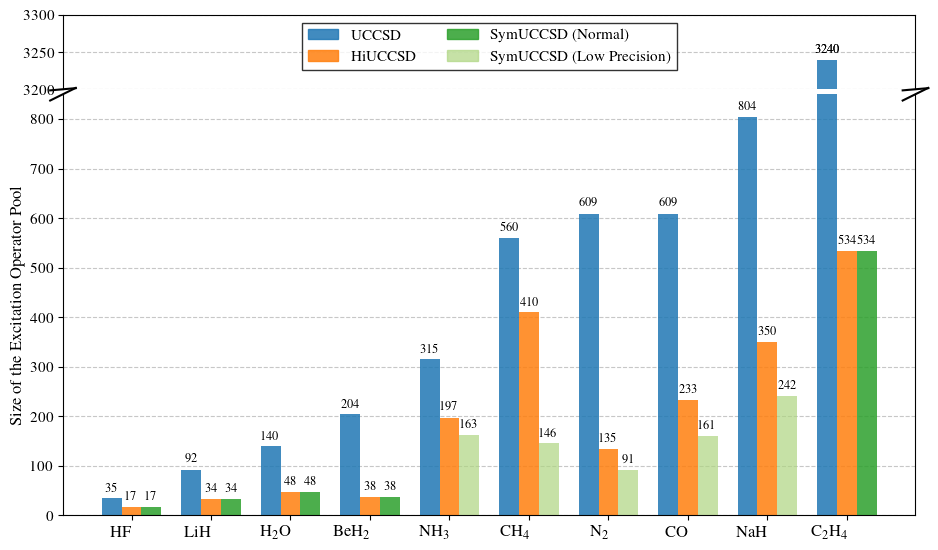

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches  # For custom legend

# Global font and LaTeX configuration
plt.rcParams['text.usetex'] = True  # Enable LaTeX rendering (LaTeX must be installed on the system)
plt.rcParams['font.family'] = 'serif'  # Serif font
plt.rcParams['font.serif'] = ['Times New Roman', 'Times']  # Prioritize Times New Roman
plt.rcParams['axes.unicode_minus'] = False  # Fix negative sign display issue

# Data
molecules = ['HF', 'LiH', r'H$_2$O', r'BeH$_2$', r'NH$_3$', r'CH$_4$', r'N$_2$', 'CO', 'NaH', r'C$_2$H$_4$']
uccsd_data = [35, 92, 140, 204, 315, 560, 609, 609, 804, 3240]
hiuccsd_data = [17, 34, 48, 38, 197, 410, 135, 233, 350, 534]
symuccsd_data = [17, 34, 48, 38, 163, 146, 91, 161, 242, 534]

# Color scheme (academically common high-distinction colors)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # Blue, Orange, Green (original SymUCCSD green)
labels = ['UCCSD', 'HiUCCSD', 'SymUCCSD']  # Base labels for three datasets

# Define indices of molecules to mark: NH3(4), CH4(5), N2(6), CO(7), NaH(8)
marked_indices = [4, 5, 6, 7, 8]
# Gray-green tones (low saturation, indicating insufficient precision; adjust as needed)
marked_color = '#6b8e23'  # Olive green (gray-green, visually implying "insufficient precision")
marked_color = '#5f9e60'  # Light gray-green (alternative)
marked_color = '#2f4f4f'  # Dark gray-green (alternative)
marked_color = '#e8f5e9'  # Very pale mint green (almost white, suitable for background/weak marking)
marked_color = '#d7eff2'  # Light cyan-green (soft with slight blue tint)
marked_color = '#e8f5e9'  # Very pale mint green (almost white, suitable for background/weak marking)
marked_color = '#d7eff2'  # Light cyan-green (soft with slight blue tint)
marked_color = '#aed581'  # Light lime green (lighter and brighter than #5f9e60)
# marked_color = '#c5e1a5'  # Pale lime green (very low saturation, prominent gray tone)
original_color = colors[2]  # Original SymUCCSD green
marked_alpha = 0.7  # Transparency of marked bars (lower than original 0.85 to enhance hierarchy)
original_alpha = 0.85

# Plot settings
x = np.arange(len(molecules))  # Label positions
width = 0.25  # Bar width

# Create figure with adjusted height ratios for upper/lower axes (lower axis 85%, upper 15% to fix scale imbalance)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                                gridspec_kw={'height_ratios': [0.15, 0.85]})  # Key: adjust height ratios

# Define y-axis ranges: ax1 (upper) only shows 3200-3300 (more compact, reduce blank space), ax2 (lower) shows 0-810
ax1.set_ylim(3200, 3300)
ax2.set_ylim(0, 850)

# Hide connecting borders between upper/lower axes to create broken axis effect
ax1.spines['bottom'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.tick_params(axis='x', which='both', bottom=False)  # Hide x-axis ticks of ax1
ax2.xaxis.tick_bottom()

# ---------------------- Core: Enlarge Y-axis tick font size ----------------------
# Set Y-axis tick font size for ax1 (upper axis) (labelsize=12, adjustable)
ax1.tick_params(axis='y', labelsize=11, width=0.8)
# Set Y-axis tick font size for ax2 (lower axis) (labelsize=12, consistent with upper axis)
ax2.tick_params(axis='y', labelsize=11, width=0.8)
# Optional: Enlarge X-axis tick font (if needed; X-axis is molecule symbols, set separately here)
ax2.tick_params(axis='x', labelsize=11, width=0.8)

# ---------------------- Plot upper axis (ax1) ----------------------
# UCCSD
rects1_1 = ax1.bar(x - width, uccsd_data, width, color=colors[0], alpha=original_alpha)
# HiUCCSD
rects2_1 = ax1.bar(x, hiuccsd_data, width, color=colors[1], alpha=original_alpha)
# SymUCCSD: plot individually, mark specified indices with gray-green (insufficient precision)
rects3_1 = []
for i in range(len(x)):
    color = marked_color if i in marked_indices else original_color
    alpha = marked_alpha if i in marked_indices else original_alpha
    rect = ax1.bar(x[i] + width, symuccsd_data[i], width, color=color, alpha=alpha)
    rects3_1.append(rect[0])  # Store each bar object

# ---------------------- Plot lower axis (ax2) ----------------------
# UCCSD
rects1_2 = ax2.bar(x - width, uccsd_data, width, color=colors[0], alpha=original_alpha)
# HiUCCSD
rects2_2 = ax2.bar(x, hiuccsd_data, width, color=colors[1], alpha=original_alpha)
# SymUCCSD: plot individually, mark specified indices with gray-green (insufficient precision)
rects3_2 = []
for i in range(len(x)):
    color = marked_color if i in marked_indices else original_color
    alpha = marked_alpha if i in marked_indices else original_alpha
    rect = ax2.bar(x[i] + width, symuccsd_data[i], width, color=color, alpha=alpha)
    rects3_2.append(rect[0])  # Store each bar object

# Draw diagonal breaks for broken axis (enhance visual effect, adjust size for narrow upper axis)
d = 0.015  # Diagonal size
kwargs = dict(transform=ax1.transAxes, color='black', clip_on=False)
ax1.plot((-d, +d), (-d, +d), **kwargs)  # Top-left diagonal
ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)  # Top-right diagonal
kwargs.update(transform=ax2.transAxes)
ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)  # Bottom-left diagonal
ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)  # Bottom-right diagonal

# Axis and title settings
# fig.suptitle('Excitation Operator Counts of Different Ansatze for Small Molecules',
#              fontsize=14, fontweight='bold', y=0.95)  # Global title, adjust y to avoid overlap
ax2.set_ylabel('Size of the Excitation Operator Pool', fontsize=12, fontweight='bold')
ax1.set_ylabel('', fontsize=12, fontweight='bold')  # Hide ylabel for upper axis to avoid duplication
ax2.set_xticks(x)
ax2.set_xticklabels(molecules, rotation=0, ha='right', fontsize=12)  # Rotate x-labels to avoid overlap

# ---------------------- Custom legend (Core: distinguish SymUCCSD normal/low precision) ----------------------
# Create base legend entries
uccsd_patch = mpatches.Patch(color=colors[0], alpha=original_alpha, label=labels[0])
hiuccsd_patch = mpatches.Patch(color=colors[1], alpha=original_alpha, label=labels[1])
symuccsd_normal_patch = mpatches.Patch(color=original_color, alpha=original_alpha, label=f'{labels[2]} (Normal)')
symuccsd_low_precision_patch = mpatches.Patch(color=marked_color, alpha=marked_alpha, label=f'{labels[2]} (Low Precision)')

# Combine legend entries and display (order: UCCSD → HiUCCSD → SymUCCSD Normal → SymUCCSD Low Precision)
legend_handles = [uccsd_patch, hiuccsd_patch, symuccsd_normal_patch, symuccsd_low_precision_patch]
ax1.legend(handles=legend_handles, 
           fontsize=11,  # Fine-tune font size to fit legend length
           frameon=True, 
           fancybox=False, 
           edgecolor='black', 
           loc='upper center',
           ncol=2)  # Display in 2 columns (optional, avoid long legend)

# Grid optimization (only keep y-axis grid for simplicity)
ax1.grid(axis='y', linestyle='--', alpha=0.7, linewidth=0.8)
ax2.grid(axis='y', linestyle='--', alpha=0.7, linewidth=0.8)
ax1.set_axisbelow(True)
ax2.set_axisbelow(True)

# Add value labels above bars (optimization: only display within current axis range to avoid invalid labels)
def add_value_labels(ax, rects, data):
    for i, rect in enumerate(rects):
        height = data[i]
        # Only display label if value is within current axis range
        if ax.get_ylim()[0] <= height <= ax.get_ylim()[1]:
            ax.annotate(f'{int(height)}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),  # Vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom',
                        fontsize=9, fontweight='medium')

# Add value labels to bars on both axes
add_value_labels(ax2, rects3_2, symuccsd_data)  # SymUCCSD on lower axis
add_value_labels(ax1, [rect for rect in rects1_1], uccsd_data)  # UCCSD on upper axis
add_value_labels(ax2, [rect for rect in rects1_2], uccsd_data)  # UCCSD on lower axis
add_value_labels(ax2, [rect for rect in rects2_2], hiuccsd_data)  # HiUCCSD on lower axis

# Only label 3240 (UCCSD for C2H4) on upper axis
add_value_labels(ax1, [rects1_1[9]], [uccsd_data[9]])

# Adjust subplot spacing to avoid overlap (reduce hspace)
plt.subplots_adjust(hspace=0.02)

# Save figure
plt.savefig('n_fops.pdf',
            format='pdf',
            dpi=300,
            bbox_inches='tight',
            facecolor='white',  # White background
            edgecolor='none')

# Optional: Display figure
plt.show()

[1] Romero, Jonathan, et al. "Strategies for quantum computing molecular energies using the unitary coupled cluster ansatz." Quantum Science and Technology 4.1 (2018): 014008.

[2] Cao, Changsu, et al. "Progress toward larger molecular simulation on a quantum computer: Simulating a system with up to 28 qubits accelerated by point-group symmetry." Physical Review A 105.6 (2022): 062452.

[3] He, Runhong, et al. "Hamiltonian-Informed Point Group Symmetry-Respecting Ansatz for Variational Quantum Eigensolver." [arXiv:2512.21087](https://doi.org/10.48550/arXiv.2512.21087) (2025).


[4] Grimsley, Harper R., et al. "An adaptive variational algorithm for exact molecular simulations on a quantum computer." Nature communications 10.1 (2019): 3007.